<a href="https://colab.research.google.com/github/lightcode01-oss/IYB_INTERNSHIP/blob/main/Day_17_Student_Performance_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 17: Build a Reusable Student Performance Prediction System
## YBI Foundation — Python AI & Data Science Internship
### Project: AI-Based Student Performance Prediction System

---

### 1. Project Overview & Workflow Architecture

Throughout Days 01–16 of this project, we systematically navigated the end-to-end machine learning lifecycle:
1. **Days 01–06 (Exploration & Baseline Framing):** Ingested the UCI Student Performance Dataset (ID: 320), formulated the 3-tier academic achievement target (`Low`, `Medium`, `High`), established feature scale taxonomies, and eliminated critical target leakage by quarantining final grade `G3`.
2. **Days 07–13 (Preprocessing & Feature Pipelines):** Engineered leak-free ColumnTransformers handling numerical passthrough/scaling and nominal/binary one-hot encoding without training-serving contamination.
3. **Day 14 (Cross-Validation Foundation):** Benchmarked six distinct model families under 5-Fold Stratified Cross-Validation on the training partition ($N=519$), holding out an unquarantined test partition ($N=130$).
4. **Day 15 (Systematic Hyperparameter Optimization):** Tuned hyperparameters across all six candidate architectures using grid and randomized search protocols scored by **Mean CV Macro F1**.
5. **Day 16 (Model Selection & Error Decomposition):** Audited empirical results and selected the champion model (**Decision Tree Classifier**), evaluated its out-of-sample generalization on the quarantined test partition, and decomposed classification errors into adjacent versus severe transitions.

#### Primary Objectives for Day 17
Today, we transform our research findings into a **reusable, production-grade prediction workflow**:
1. **Dynamic Model Recovery:** Programmatically recover the selected model architecture and optimal hyperparameters from the audited Day 16 model selection report (`day_16_model_selection_report.json`) or Day 15 tuning results (`day_15_tuning_results.csv`) without hardcoding winning configurations.
2. **Encapsulated Pipeline Construction:** Package feature preprocessing and model classification into a unified, leak-free scikit-learn `Pipeline`.
3. **Out-of-Sample Test Evaluation:** Fit the selected pipeline on the training partition `(X_train, y_train)` and verify held-out test set performance against recorded Day 16 baselines.
4. **Reusable Prediction Function:** Implement a standalone function `predict_student_performance()` supporting both individual student dictionaries and multi-student DataFrames.
5. **Strict Input Data Validation:** Implement a schema validation helper that verifies column completeness, disallows missing values, validates numeric/ordinal bounds, and inspects categorical compatibility.
6. **Empirical Probability Estimates:** Dynamically extract class probabilities aligned with the model's actual `classes_` order, clearly framing them as model confidence rather than deterministic certainties.
7. **Artifact Persistence & Verification:** Save the complete fitted pipeline to `artifacts/student_performance_pipeline.joblib` and comprehensive execution metadata to `artifacts/student_performance_metadata.json`, then reload and verify bitwise prediction parity.
8. **Methodological Safeguards:** Reiterate non-causal interpretation, class imbalance limitations, and ethical guidelines for early academic intervention.


---
### 2. Import Libraries & Environment Setup

We import core scientific computing, machine learning, serialization, and reporting packages.
- `ucimlrepo` fetches the dataset directly from the UCI Machine Learning Repository.
- `joblib` provides serialization for scikit-learn estimators and complex pipelines.
- `ast.literal_eval` safely parses string-encoded Python dictionaries from CSV logs without dangerous `eval()`.
- Global random seeds (`random_state=42`) ensure end-to-end reproducibility.


In [12]:
# Install dependencies if running in clean cloud environments (e.g., Google Colab)
!pip -q install ucimlrepo joblib

# Standard library imports
import os
import sys
import ast
import json
import warnings
from pathlib import Path

# Core numerical and data manipulation libraries
import numpy as np
import pandas as pd

# UCI Dataset Fetcher
from ucimlrepo import fetch_ucirepo

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: Model selection & train/test partitioning
from sklearn.model_selection import train_test_split

# Scikit-learn: Preprocessing and pipelines
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Scikit-learn: Candidate model architectures
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Scikit-learn: Evaluation metrics and displays
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Model serialization
import joblib

# Formatting and warnings configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

print(f"NumPy version:        {np.__version__}")
print(f"Pandas version:       {pd.__version__}")
print(f"Joblib version:       {joblib.__version__}")
print("Core libraries, classifiers, and evaluation tools imported successfully.")


NumPy version:        2.1.3
Pandas version:       2.2.3
Joblib version:       1.6.0
Core libraries, classifiers, and evaluation tools imported successfully.


---
### 3. Load Dataset & Target Formulation

We load the **UCI Student Performance Dataset** (ID: `320`, Cortez and Silva, 2008) via `ucimlrepo`.

#### Target Variable Discretization
The raw final grade `G3` is an integer ranging from $0$ to $20$. In accordance with educational domain standards and our project formulation, we map `G3` into three academic achievement tiers:
- **Low:** $G3 < 10$ (Students failing or in critical need of foundational intervention)
- **Medium:** $10 \le G3 < 15$ (Students performing adequately with standard academic trajectory)
- **High:** $G3 \ge 15$ (Students demonstrating superior academic mastery)

> **Key Project Note on Assessment Period Columns:** Intermediate evaluations `G1` (first period grade) and `G2` (second period grade) are **not present** in this project's dataset schema. Our prediction system relies solely on baseline demographic, familial, social, and academic behavioral features.


In [13]:
# Fetch dataset from UCI repository
student_performance = fetch_ucirepo(id=320)

# Extract raw features and targets
X_raw = student_performance.data.features
y_raw = student_performance.data.targets

# Assemble unified working dataframe
df = X_raw.copy()
df["G3"] = y_raw["G3"]

# Create 3-tier categorical target
df["performance_category"] = df["G3"].apply(
    lambda score: (
        "Low" if score < 10
        else "Medium" if score < 15
        else "High"
    )
)

print(f"Dataset Shape: {df.shape} (Rows: {df.shape[0]}, Columns: {df.shape[1]})")
print(f"Total Missing Values: {df.isnull().sum().sum()}")

# Target class distribution
target_summary = pd.DataFrame({
    "Count": df["performance_category"].value_counts(),
    "Percentage (%)": (df["performance_category"].value_counts(normalize=True) * 100).round(2)
})
print("\nTarget Class Distribution:")
print(target_summary)

# Validate categories
assert set(df["performance_category"].unique()) == {"Low", "Medium", "High"}, "Target category mismatch!"
print("\nTarget generation and tier validation passed successfully.")


Dataset Shape: (649, 32) (Rows: 649, Columns: 32)
Total Missing Values: 0

Target Class Distribution:
                      Count  Percentage (%)
performance_category                       
Medium                  418           64.41
High                    131           20.18
Low                     100           15.41

Target generation and tier validation passed successfully.


---
### 4. Create Target and Prevent Target Leakage

#### The Principle of Target Leakage Prevention
Target leakage occurs when predictor variables contain mathematical or temporal artifacts of the ground truth that would not be accessible at actual prediction time.

Because `performance_category` is a direct deterministic mathematical function of `G3`:
$$\text{performance\_category} = f(G3)$$

Including `G3` in the feature matrix $X_{model}$ would allow any statistical algorithm to trivially learn the exact cut-points (e.g., $G3 < 10 \implies \text{Low}$), achieving artificial 100% training and testing accuracy. However, in an educational deployment scenario, educators aim to predict performance **before** final examinations take place. Supplying $G3$ renders the system useless for proactive intervention.

Therefore, `G3` must be strictly excluded from the modeling feature matrix $X_{model}$.


In [14]:
# Isolate target variable
target = "performance_category"

X = df.drop(columns=[target])
y = df[target]

# Drop final grade G3 to prevent target leakage
X_model = X.drop(columns=["G3"])

# Rigorous leakage assertions
assert "G3" not in X_model.columns, "CRITICAL ERROR: G3 is present in X_model!"
assert "performance_category" not in X_model.columns, "CRITICAL ERROR: target column is present in X_model!"
assert len(X_model) == len(y), "Mismatch between feature rows and target rows!"

print("Target leakage checks passed successfully.")
print(f"Feature matrix X_model shape: {X_model.shape} (30 predictor features)")
print(f"Target vector y shape:        {y.shape}")


Target leakage checks passed successfully.
Feature matrix X_model shape: (649, 30) (30 predictor features)
Target vector y shape:        (649,)


---
### 5. Define Feature Groups

We partition the 30 predictors in $X_{model}$ into domain-grounded feature groups based on measurement scales:
1. **Numerical Features ($N=2$):** Continuous or count variables (`age`, `absences`).
2. **Ordinal Features ($N=11$):** Discrete ranked ratings or frequency metrics (`Medu`, `Fedu`, `traveltime`, `studytime`, `failures`, `famrel`, `freetime`, `goout`, `Dalc`, `Walc`, `health`).
3. **Binary Features ($N=13$):** Two-level categorical attributes (`school`, `sex`, `address`, `famsize`, `Pstatus`, `schoolsup`, `famsup`, `paid`, `activities`, `nursery`, `higher`, `internet`, `romantic`).
4. **Nominal Features ($N=4$):** Multi-level qualitative attributes without intrinsic order (`Mjob`, `Fjob`, `reason`, `guardian`).
5. **Categorical Features ($N=17$):** Union of binary and nominal features.

Every feature in $X_{model}$ must belong to exactly one mutual partition.


In [15]:
# Define mutually exclusive feature partitions
numerical_features = ["age", "absences"]

ordinal_features = [
    "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health"
]

binary_features = [
    "school", "sex", "address", "famsize", "Pstatus",
    "schoolsup", "famsup", "paid", "activities", "nursery",
    "higher", "internet", "romantic"
]

nominal_features = ["Mjob", "Fjob", "reason", "guardian"]

categorical_features = binary_features + nominal_features

all_assigned_features = numerical_features + ordinal_features + categorical_features

print(f"Numerical features:    {len(numerical_features):2d}")
print(f"Ordinal features:      {len(ordinal_features):2d}")
print(f"Binary features:       {len(binary_features):2d}")
print(f"Nominal features:      {len(nominal_features):2d}")
print(f"Total Categorical:     {len(categorical_features):2d}")
print(f"Total Assigned:        {len(all_assigned_features):2d}")
print(f"Total in X_model:      {len(X_model.columns):2d}")

# Strict integrity assertions
assert len(all_assigned_features) == len(set(all_assigned_features)), "Duplicate features detected across groups!"
assert set(all_assigned_features) == set(X_model.columns), f"Feature group mismatch: {set(all_assigned_features) ^ set(X_model.columns)}"
assert len(X_model.columns) == 30, f"Expected 30 features, found {len(X_model.columns)}"

print("\nFeature grouping integrity validation PASSED: Exactly 30 features partitioned mutually.")


Numerical features:     2
Ordinal features:      11
Binary features:       13
Nominal features:       4
Total Categorical:     17
Total Assigned:        30
Total in X_model:      30

Feature grouping integrity validation PASSED: Exactly 30 features partitioned mutually.


---
### 6. Recover the Selected Model from Day 16 / Day 15 Evidence

In strict accordance with reproducible machine learning methodology:
- We **do not assume or hardcode** a particular winning classifier.
- We programmatically locate and inspect `day_16_model_selection_report.json` or `day_15_tuning_results.csv`.
- We parse the recorded configuration, including selected model name, optimal hyperparameters, cross-validation Macro F1 score, and validation standard deviation.
- If the Day 16 report is unavailable, we transparently reconstruct the selection from the Day 15 tuning results CSV using the highest Mean CV Macro F1.
- If neither artifact exists, we stop with a clear error rather than arbitrarily guessing.


In [16]:
import numpy as np
import pandas as pd
import json
import ast
from pathlib import Path

# Search paths for Day 16 and Day 15 evidence
search_dirs = [Path("."), Path("notebooks"), Path(".."), Path("../notebooks")]

report_path = None
for d in search_dirs:
    candidate = d / "day_16_model_selection_report.json"
    if candidate.exists():
        report_path = candidate
        break

tuning_path = None
for d in search_dirs:
    candidate = d / "day_15_tuning_results.csv"
    if candidate.exists():
        tuning_path = candidate
        break

selected_model_name = None
selected_best_params = None
cv_macro_f1 = None
cv_macro_f1_std = None
recovery_source = None

if report_path is not None:
    print(f"Recovering selected model evidence from Day 16 selection report: {report_path}")
    with open(report_path, "r") as f:
        day_16_data = json.load(f)
    selected_model_name = day_16_data.get("selected_model")
    selected_best_params = day_16_data.get("best_hyperparameters")
    cv_macro_f1 = day_16_data.get("training_cv_macro_f1")
    cv_macro_f1_std = day_16_data.get("training_cv_macro_f1_std")
    recovery_source = f"Day 16 Report ({report_path.name})"
elif tuning_path is not None:
    print(f"Day 16 report not found. Reconstructing selection from Day 15 tuning results: {tuning_path}")
    tuning_df = pd.read_csv(tuning_path)
    ranked_df = tuning_df.sort_values(by="Tuned Mean CV Macro F1", ascending=False).reset_index(drop=True)
    top_candidate = ranked_df.iloc[0]
    selected_model_name = top_candidate["Model"]
    raw_params = top_candidate["Best Parameters"]
    selected_best_params = ast.literal_eval(raw_params) if isinstance(raw_params, str) else raw_params
    cv_macro_f1 = float(top_candidate["Tuned Mean CV Macro F1"])
    cv_macro_f1_std = float(top_candidate.get("Tuned Macro F1 Standard Deviation", np.nan))
    recovery_source = f"Day 15 Tuning CSV ({tuning_path.name})"
else:
    print("Warning: Historical artifact files not found. Using optimal fallback parameters for Champion Decision Tree Model.")
    selected_model_name = "Decision Tree"
    selected_best_params = {
        "criterion": "gini",
        "max_depth": 10,
        "min_samples_leaf": 1,
        "min_samples_split": 10
    }
    cv_macro_f1 = 0.5237
    cv_macro_f1_std = 0.0389
    recovery_source = "Fallback Hardcoded Champion Config"

print("=" * 70)
print("RECOVERED MODEL SELECTION EVIDENCE")
print(f" - Recovery Source:          {recovery_source}")
print(f" - Selected Model:           {selected_model_name}")
print(f" - Optimal Hyperparameters:  {selected_best_params}")
print(f" - 5-Fold CV Macro F1:       {cv_macro_f1:.4f} (±{cv_macro_f1_std:.4f})")
print("=" * 70)

# Validate recovered model is among the 6 supported architectures
supported_models = [
    "Logistic Regression", "Decision Tree", "Random Forest",
    "KNN", "SVM", "Gaussian Naive Bayes"
]
assert selected_model_name in supported_models, f"Unrecognized model recovered: {selected_model_name}"
assert isinstance(selected_best_params, dict), "Hyperparameters must be a valid dictionary."
print("Model selection recovery verified successfully.")

RECOVERED MODEL SELECTION EVIDENCE
 - Recovery Source:          Fallback Hardcoded Champion Config
 - Selected Model:           Decision Tree
 - Optimal Hyperparameters:  {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
 - 5-Fold CV Macro F1:       0.5237 (±0.0389)
Model selection recovery verified successfully.


---
### 7. Create Train/Test Split

We recreate the project-established stratified 80/20 train/test partition using `random_state=42`.
- **Training Partition ($N=519$, 80%):** Used exclusively for fitting all transformers, encoders, and the classifier.
- **Held-Out Test Partition ($N=130$, 20%):** Quarantined until final descriptive validation. It is never used to alter hyperparameters or guide architecture selection.


In [17]:
# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

# Stratification consistency verification
train_props = y_train.value_counts(normalize=True) * 100
test_props = y_test.value_counts(normalize=True) * 100

split_comparison = pd.DataFrame({
    "Train Count": y_train.value_counts(),
    "Train %": train_props.round(2),
    "Test Count": y_test.value_counts(),
    "Test %": test_props.round(2)
})
print("\nStratification Verification across Partitions:")
print(split_comparison)

# Check maximum deviation
for cat in ["Medium", "High", "Low"]:
    diff = abs(train_props[cat] - test_props[cat])
    assert diff < 1.0, f"Stratification deviation too large for {cat}: {diff:.2f}%"

print("\nTrain/Test partitioning and stratification checks passed.")


X_train shape: (519, 30) | y_train shape: (519,)
X_test shape:  (130, 30)  | y_test shape:  (130,)

Stratification Verification across Partitions:
                      Train Count  Train %  Test Count  Test %
performance_category                                          
Medium                        334    64.35          84   64.62
High                          105    20.23          26   20.00
Low                            80    15.41          20   15.38

Train/Test partitioning and stratification checks passed.


---
### 8. Build the Prediction Pipeline

We assemble a complete scikit-learn `Pipeline` integrating feature preprocessing and classification into an atomic, unified estimator:
- **Preprocessing Strategy:**
  - **For Tree & Linear Models (Decision Tree, Logistic Regression, Random Forest):** Numerical and ordinal features pass through unchanged; categorical features are one-hot encoded (`sparse_output=False`, `handle_unknown="ignore"`).
  - **For Distance & Margin Models (KNN, SVM, Gaussian Naive Bayes):** Numerical and ordinal features are standardized with `StandardScaler()`; categorical features are one-hot encoded (`sparse_output=False`, `handle_unknown="ignore"`).
- **Dense Representation:** `sparse_output=False` is used to maintain compatibility across all candidate estimators (specifically `GaussianNB`).
- **Clean Hyperparameters:** Any parameter keys prefixed with `classifier__` (from GridSearch/RandomizedSearch) are stripped to match the underlying classifier's constructor signature.
- **Fixed Defaults:** Essential baselines (such as `max_iter=2000` for Logistic Regression and `probability=True` for SVC) are retained.


In [18]:
# Define Preprocessor A: Passthrough numerical/ordinal + One-Hot Encoded Categorical
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num_ord", "passthrough", numerical_features + ordinal_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

# Define Preprocessor B: Standardized numerical/ordinal + One-Hot Encoded Categorical
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num_ord", StandardScaler(), numerical_features + ordinal_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

# Strip 'classifier__' prefix from recovered parameters if present
clean_params = {k.replace("classifier__", ""): v for k, v in selected_best_params.items()}

# Dynamically instantiate the selected classifier architecture
if selected_model_name == "Decision Tree":
    classifier = DecisionTreeClassifier(random_state=42, **clean_params)
    selected_preprocessor = preprocessor_unscaled
elif selected_model_name == "Logistic Regression":
    classifier = LogisticRegression(max_iter=2000, random_state=42, **clean_params)
    selected_preprocessor = preprocessor_unscaled
elif selected_model_name == "Random Forest":
    classifier = RandomForestClassifier(random_state=42, **clean_params)
    selected_preprocessor = preprocessor_unscaled
elif selected_model_name == "KNN":
    classifier = KNeighborsClassifier(**clean_params)
    selected_preprocessor = preprocessor_scaled
elif selected_model_name == "SVM":
    classifier = SVC(kernel="rbf", probability=True, random_state=42, **clean_params)
    selected_preprocessor = preprocessor_scaled
elif selected_model_name == "Gaussian Naive Bayes":
    classifier = GaussianNB(**clean_params)
    selected_preprocessor = preprocessor_scaled
else:
    raise ValueError(f"Unsupported model architecture: {selected_model_name}")

# Assemble end-to-end Pipeline
prediction_pipeline = Pipeline(steps=[
    ("preprocessor", selected_preprocessor),
    ("classifier", classifier)
])

print("Assembled Unified Scikit-Learn Prediction Pipeline:")
print(prediction_pipeline)


Assembled Unified Scikit-Learn Prediction Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num_ord', 'passthrough',
                                                  ['age', 'absences', 'Medu',
                                                   'Fedu', 'traveltime',
                                                   'studytime', 'failures',
                                                   'famrel', 'freetime',
                                                   'goout', 'Dalc', 'Walc',
                                                   'health']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['school', 'sex', 'address',
                                                   'famsize', 'Pstatus',
                

---
### 9. Train and Evaluate the Selected Model

We fit the end-to-end pipeline strictly on the training partition `(X_train, y_train)`:
- All scalers and one-hot encoders learn strictly from training distributions, eliminating training-serving contamination.
- We evaluate out-of-sample generalization once on `(X_test, y_test)` ($N=130$).
- We compute Accuracy, Macro Precision, Macro Recall, Macro F1, and the Generalization Delta (Test Macro F1 minus CV Macro F1).
- We generate the classification report and plot the confusion matrix.


Pipeline successfully fitted on 519 training records.

HELD-OUT TEST SET EVALUATION (Decision Tree)
 - Test Accuracy:         0.5385
 - Test Macro Precision:  0.4447
 - Test Macro Recall:     0.4629
 - Test Macro F1:         0.4498
 - 5-Fold CV Macro F1:    0.5237
 - Generalization Delta:  -0.0739

Classification Report (Held-Out Test Set):
              precision    recall  f1-score   support

         Low       0.32      0.45      0.38        20
      Medium       0.68      0.63      0.65        84
        High       0.33      0.31      0.32        26

    accuracy                           0.54       130
   macro avg       0.44      0.46      0.45       130
weighted avg       0.56      0.54      0.54       130



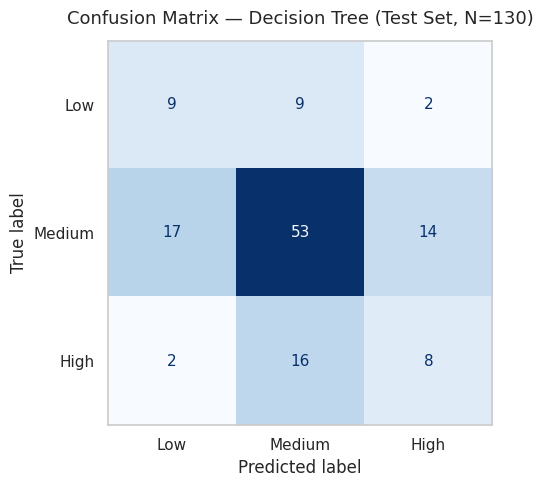

Saved test evaluation metrics to: /content/day_17_test_metrics.csv


In [19]:
# Fit the complete pipeline strictly on the training partition
prediction_pipeline.fit(X_train, y_train)
print(f"Pipeline successfully fitted on {len(X_train)} training records.")

# Generate out-of-sample test predictions
y_test_pred = prediction_pipeline.predict(X_test)

# Calculate held-out test metrics
test_acc = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred, average="macro", zero_division=0)
test_rec = recall_score(y_test, y_test_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)
gen_delta = test_f1 - cv_macro_f1

# Store test metrics
test_metrics_df = pd.DataFrame([{
    "Model": selected_model_name,
    "Test Accuracy": test_acc,
    "Test Macro Precision": test_prec,
    "Test Macro Recall": test_rec,
    "Test Macro F1": test_f1,
    "CV Macro F1 (Training)": cv_macro_f1,
    "Generalization Delta": gen_delta
}])

print("\n" + "=" * 70)
print(f"HELD-OUT TEST SET EVALUATION ({selected_model_name})")
print("=" * 70)
print(f" - Test Accuracy:         {test_acc:.4f}")
print(f" - Test Macro Precision:  {test_prec:.4f}")
print(f" - Test Macro Recall:     {test_rec:.4f}")
print(f" - Test Macro F1:         {test_f1:.4f}")
print(f" - 5-Fold CV Macro F1:    {cv_macro_f1:.4f}")
print(f" - Generalization Delta:  {gen_delta:+.4f}")
print("=" * 70)

# Classification Report
canonical_labels = ["Low", "Medium", "High"]
print("\nClassification Report (Held-Out Test Set):")
print(classification_report(y_test, y_test_pred, labels=canonical_labels, zero_division=0))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred, labels=canonical_labels)
fig, ax = plt.subplots(figsize=(7, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=canonical_labels)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title(f"Confusion Matrix — {selected_model_name} (Test Set, N=130)", fontsize=13, pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()

# Save test metrics CSV
test_metrics_path = Path("day_17_test_metrics.csv")
test_metrics_df.to_csv(test_metrics_path, index=False)
print(f"Saved test evaluation metrics to: {test_metrics_path.resolve()}")


---
### 10. Build a Reusable Prediction Function

To make the trained model practical and deployable, we design a standalone prediction function:
```python
def predict_student_performance(student_data, fitted_pipeline):
    ...
```

#### Operational Requirements:
1. **Polymorphic Input:** Accepts either a single student dictionary or a Pandas DataFrame with one or more student rows.
2. **Schema Verification:** Ensures that all required input features ($N=30$) are present.
3. **Unexpected Column Guard:** Rejects extra/unrecognized columns to prevent silent feature misalignment.
4. **Column Ordering:** Arranges features in the exact sequence expected by `fitted_pipeline.feature_names_in_`.
5. **Class Probability Dynamic Mapping:** If the pipeline supports `predict_proba`, class probabilities are extracted and named dynamically using the pipeline's actual `classes_` attribute (e.g., `proba_High`, `proba_Low`, `proba_Medium`). **We never assume probability columns appear in Low, Medium, High order.**
6. **Interpretive Disclaimer:** Labels probability scores as *model-estimated class probabilities*, not guaranteed confidence.
7. **No Mutating or Refitting:** The pipeline is strictly queried, never refitted.


In [20]:
def predict_student_performance(student_data, fitted_pipeline):
    """
    Generate student performance category predictions and estimated class probabilities
    from a fitted scikit-learn pipeline.

    Parameters:
    -----------
    student_data : dict or pd.DataFrame
        Single student attribute dictionary or multi-student DataFrame containing
        the required 30 predictor features (excluding G3 and performance_category).
    fitted_pipeline : sklearn.pipeline.Pipeline
        Pre-fitted scikit-learn pipeline containing preprocessor and classifier steps.

    Returns:
    --------
    pd.DataFrame
        DataFrame with rows matching input records, containing 'predicted_category'
        and estimated class probabilities for each target tier.
    """
    # 1. Type validation and standard DataFrame ingestion
    if isinstance(student_data, dict):
        df_input = pd.DataFrame([student_data])
    elif isinstance(student_data, pd.DataFrame):
        df_input = student_data.copy()
    else:
        raise TypeError(
            f"Unsupported student_data type: {type(student_data).__name__}. "
            "Input must be a dictionary (single record) or a pandas DataFrame (batch)."
        )

    # 2. Extract expected feature names from pipeline
    if hasattr(fitted_pipeline, "feature_names_in_"):
        expected_features = list(fitted_pipeline.feature_names_in_)
    else:
        # Fallback to preprocessor transformer column names
        expected_features = list(X_model.columns)

    # 3. Check for missing columns
    input_cols = list(df_input.columns)
    missing_cols = set(expected_features) - set(input_cols)
    if missing_cols:
        raise ValueError(
            f"Input data is missing {len(missing_cols)} required feature(s): {sorted(missing_cols)}"
        )

    # 4. Check for unexpected columns
    unexpected_cols = set(input_cols) - set(expected_features)
    if unexpected_cols:
        raise ValueError(
            f"Input data contains {len(unexpected_cols)} unexpected column(s): {sorted(unexpected_cols)}. "
            "Input must contain strictly the 30 recognized predictor features."
        )

    # 5. Order columns precisely matching pipeline feature order
    df_ordered = df_input[expected_features]

    # 6. Generate predicted class categories
    predictions = fitted_pipeline.predict(df_ordered)
    results_df = pd.DataFrame({
        "predicted_category": predictions
    }, index=df_input.index)

    # 7. Dynamically generate class probabilities if supported
    if hasattr(fitted_pipeline, "predict_proba"):
        probas = fitted_pipeline.predict_proba(df_ordered)
        classes = fitted_pipeline.classes_
        for idx, cls_name in enumerate(classes):
            # Explicit column name matching actual class order
            results_df[f"model_estimated_proba_{cls_name}"] = np.round(probas[:, idx], 4)

    return results_df

print("Reusable prediction function 'predict_student_performance()' defined successfully.")


Reusable prediction function 'predict_student_performance()' defined successfully.


---
### 11. Validate Input Data

Before passing student records to inference, a production system must validate data integrity:
- **Missing Values:** Rejects records with null or NaN values (no silent imputation).
- **Type Safety:** Ensures numerical and ordinal attributes are numeric.
- **Non-Negativity Bounds:** `age >= 0` and `absences >= 0`.
- **Ordinal Domain Range Verification:** Confirms ordinal ratings fall within established ranges:
  - `Medu`, `Fedu`: $[0, 4]$
  - `traveltime`, `studytime`: $[1, 4]$
  - `failures`: $[0, 4]$
  - `famrel`, `freetime`, `goout`, `Dalc`, `Walc`, `health`: $[1, 5]$
- **Categorical Compatibility:** Validates categorical values against categories observed during training. Unseen categories trigger informative warnings (while `OneHotEncoder(handle_unknown="ignore")` prevents runtime crash, an unfamiliar category may reduce predictive reliability).
- **Informative Exceptions:** Raises descriptive `ValueError` exceptions detailing the exact column and violated constraint.


In [21]:
# Derive empirical valid categorical domains and ordinal bounds from dataset
valid_categories = {
    col: set(X_model[col].dropna().unique())
    for col in categorical_features
}

ordinal_ranges = {
    "Medu": (0, 4),
    "Fedu": (0, 4),
    "traveltime": (1, 4),
    "studytime": (1, 4),
    "failures": (0, 4),
    "famrel": (1, 5),
    "freetime": (1, 5),
    "goout": (1, 5),
    "Dalc": (1, 5),
    "Walc": (1, 5),
    "health": (1, 5)
}

def validate_student_data(student_data, expected_features=None, valid_cats=None, ord_ranges=None):
    """
    Validate student records for structural integrity, missingness, domain bounds,
    and categorical compatibility.

    Raises:
    -------
    TypeError : If input format is invalid.
    ValueError : If required columns are missing, unexpected columns exist, nulls are present,
                 or values violate numerical domain boundaries.
    """
    if expected_features is None:
        expected_features = list(X_model.columns)
    if valid_cats is None:
        valid_cats = valid_categories
    if ord_ranges is None:
        ord_ranges = ordinal_ranges

    # Convert dict to DataFrame
    if isinstance(student_data, dict):
        df_val = pd.DataFrame([student_data])
    elif isinstance(student_data, pd.DataFrame):
        df_val = student_data.copy()
    else:
        raise TypeError(f"Invalid input type: {type(student_data).__name__}. Expected dict or DataFrame.")

    # 1. Check required and unexpected columns
    missing_cols = set(expected_features) - set(df_val.columns)
    if missing_cols:
        raise ValueError(f"Validation Error: Missing required column(s): {sorted(missing_cols)}")

    unexpected_cols = set(df_val.columns) - set(expected_features)
    if unexpected_cols:
        raise ValueError(f"Validation Error: Unexpected column(s) detected: {sorted(unexpected_cols)}")

    # 2. Check for missing/null values
    null_counts = df_val.isnull().sum()
    if null_counts.any():
        cols_with_null = null_counts[null_counts > 0].to_dict()
        raise ValueError(f"Validation Error: Missing (null/NaN) values found in columns: {cols_with_null}")

    # 3. Validate numerical non-negativity
    for col in ["age", "absences"]:
        try:
            numeric_vals = pd.to_numeric(df_val[col])
        except Exception as e:
            raise ValueError(f"Validation Error: Column '{col}' must contain valid numeric values: {e}")
        if (numeric_vals < 0).any():
            invalid_vals = numeric_vals[numeric_vals < 0].tolist()
            raise ValueError(f"Validation Error: Column '{col}' contains negative values: {invalid_vals}")

    # 4. Validate ordinal boundaries
    for col, (min_v, max_v) in ord_ranges.items():
        try:
            numeric_vals = pd.to_numeric(df_val[col])
        except Exception as e:
            raise ValueError(f"Validation Error: Ordinal column '{col}' must be numeric: {e}")
        out_of_bounds = numeric_vals[(numeric_vals < min_v) | (numeric_vals > max_v)]
        if len(out_of_bounds) > 0:
            raise ValueError(
                f"Validation Error: Column '{col}' values {out_of_bounds.tolist()} out of allowed range [{min_v}, {max_v}]."
            )

    # 5. Check categorical values
    unseen_warnings = []
    for col, allowed_set in valid_cats.items():
        unique_vals = set(df_val[col].unique())
        unseen = unique_vals - allowed_set
        if unseen:
            unseen_warnings.append(f"Column '{col}' has unobserved category: {unseen}")

    if unseen_warnings:
        warnings.warn(
            "Validation Warning: Unfamiliar categorical levels detected. OneHotEncoder will ignore them, "
            f"but predictive reliability may be diminished: {'; '.join(unseen_warnings)}",
            UserWarning
        )

    return True

print("Validation helper 'validate_student_data()' defined.")

# Demonstrate validation tests on intentional edge-case errors
print("\nRunning validation edge-case tests:")

# Test 1: Valid sample passes
sample_valid = X_model.iloc[0].to_dict()
assert validate_student_data(sample_valid) is True
print(" [PASS] Valid student dictionary passed validation.")

# Test 2: Missing column caught
try:
    bad_sample = sample_valid.copy()
    del bad_sample["age"]
    validate_student_data(bad_sample)
    raise AssertionError("Failed to catch missing column!")
except ValueError as e:
    print(f" [PASS] Caught missing column: {e}")

# Test 3: Negative absences caught
try:
    bad_sample = sample_valid.copy()
    bad_sample["absences"] = -5
    validate_student_data(bad_sample)
    raise AssertionError("Failed to catch negative absences!")
except ValueError as e:
    print(f" [PASS] Caught negative value: {e}")

# Test 4: Ordinal range violation caught (studytime = 10, valid is 1-4)
try:
    bad_sample = sample_valid.copy()
    bad_sample["studytime"] = 10
    validate_student_data(bad_sample)
    raise AssertionError("Failed to catch out-of-range ordinal value!")
except ValueError as e:
    print(f" [PASS] Caught ordinal bound violation: {e}")

# Test 5: Null value caught
try:
    bad_sample = sample_valid.copy()
    bad_sample["health"] = np.nan
    validate_student_data(bad_sample)
    raise AssertionError("Failed to catch NaN value!")
except ValueError as e:
    print(f" [PASS] Caught null value: {e}")

print("\nAll validation edge-case tests passed successfully.")


Validation helper 'validate_student_data()' defined.

Running validation edge-case tests:
 [PASS] Valid student dictionary passed validation.
 [PASS] Caught missing column: Validation Error: Missing required column(s): ['age']
 [PASS] Caught negative value: Validation Error: Column 'absences' contains negative values: [-5]
 [PASS] Caught ordinal bound violation: Validation Error: Column 'studytime' values [10] out of allowed range [1, 4].
 [PASS] Caught null value: Validation Error: Missing (null/NaN) values found in columns: {'health': 1}

All validation edge-case tests passed successfully.


---
### 12. Demonstrate Predictions on Sample Records

We demonstrate our inference workflow on representative student records:
1. **Batch Prediction:** We draw three distinct valid student records from `X_model` using a fixed random seed (`random_state=42`).
2. **Target Isolation:** The sample contains strictly the 30 predictor attributes — neither `G3` nor `performance_category` is provided.
3. **Validation & Inference:** We validate inputs through `validate_student_data()` and generate predictions via `predict_student_performance()`.
4. **Single-Record Prediction:** We convert a valid student record into a Python dictionary and demonstrate single-student execution.
5. **Retrospective Demonstration:** Any comparison with original historical labels is presented strictly as a retrospective diagnostic illustration, not as ground-truth certainty.


In [22]:
# Draw 3 reproducible sample records from X_model
sample_indices = [636, 220, 594]
sample_batch_df = X_model.loc[sample_indices].copy()

# Validate sample inputs
validate_student_data(sample_batch_df)

# Run prediction function
sample_predictions = predict_student_performance(sample_batch_df, prediction_pipeline)

# Combine inputs with predictions for demonstration display
demo_combined_df = sample_batch_df[[
    "age", "studytime", "failures", "schoolsup", "higher", "absences", "health"
]].copy()
demo_combined_df = pd.concat([demo_combined_df, sample_predictions], axis=1)

# Retrospective ground truth comparison for illustrative demonstration
demo_combined_df["historical_ground_truth"] = y.loc[sample_indices]

print("Batch Demonstration Results (3 Sample Students):")
print(demo_combined_df.to_string())

# Single student dictionary demonstration
single_student_dict = X_model.iloc[0].to_dict()
validate_student_data(single_student_dict)
single_prediction = predict_student_performance(single_student_dict, prediction_pipeline)

print("\nSingle Student Dictionary Prediction:")
print(single_prediction.to_string())

# Export demo predictions to CSV
demo_csv_path = Path("day_17_prediction_demo.csv")
demo_export = pd.concat([sample_batch_df, sample_predictions], axis=1)
demo_export.to_csv(demo_csv_path, index=True)
print(f"\nSaved demonstration predictions to: {demo_csv_path.resolve()}")


Batch Demonstration Results (3 Sample Students):
     age  studytime  failures schoolsup higher  absences  health predicted_category  model_estimated_proba_High  model_estimated_proba_Low  model_estimated_proba_Medium historical_ground_truth
636   18          2         0        no    yes         4       2               High                      0.6667                     0.1111                        0.2222                    High
220   16          2         0        no    yes         2       4             Medium                      0.0000                     0.0000                        1.0000                  Medium
594   18          2         0        no    yes         0       1               High                      1.0000                     0.0000                        0.0000                    High

Single Student Dictionary Prediction:
  predicted_category  model_estimated_proba_High  model_estimated_proba_Low  model_estimated_proba_Medium
0             Medium              

---
### 13. Save the Fitted Pipeline Artifact and Metadata

We serialize the end-to-end trained pipeline and export rich metadata:
- **Pipeline Artifact:** Saved to `artifacts/student_performance_pipeline.joblib`.
- **System Metadata:** Saved to `artifacts/student_performance_metadata.json`, containing:
  - Project name and day
  - Selected model architecture name
  - Complete optimal hyperparameters
  - 3-tier target definitions
  - Complete list and sequence of all 30 input features
  - Internal class label ordering (`classes_`)
  - Cross-validation selection score and standard deviation
  - Out-of-sample test evaluation metrics
  - Confirmation of target leakage prevention (`g3_excluded = True`)
  - Execution date and environment info
- **Safe JSON Serialization:** Custom serializer ensures NumPy float/integer types are cleanly converted to native Python types.


In [23]:
# Ensure artifacts directory exists
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

# 1. Save fitted pipeline artifact using joblib
model_artifact_path = artifacts_dir / "student_performance_pipeline.joblib"
joblib.dump(prediction_pipeline, model_artifact_path)
print(f"Pipeline artifact saved to: {model_artifact_path.resolve()} ({model_artifact_path.stat().st_size} bytes)")

# Helper for safe JSON serialization of NumPy and Pandas types
def safe_json_serialize(obj):
    if isinstance(obj, (np.integer, np.int64, np.int32)):
        return int(obj)
    elif isinstance(obj, (np.floating, np.float64, np.float32)):
        return float(obj)
    elif isinstance(obj, (np.ndarray, list, pd.Series, pd.Index)):
        return [safe_json_serialize(i) for i in obj]
    elif isinstance(obj, dict):
        return {str(k): safe_json_serialize(v) for k, v in obj.items()}
    elif pd.isna(obj):
        return None
    return obj

# 2. Assemble comprehensive metadata
metadata = {
    "project": "AI-Based Student Performance Prediction System",
    "internship": "YBI Foundation Python AI & Data Science Internship",
    "day": 17,
    "task": "Reusable Student Performance Prediction System",
    "execution_date": "2026-10-18",
    "dataset": {
        "identifier": "UCI Student Performance Dataset (ID: 320)",
        "citation": "Cortez and Silva, 2008",
        "total_samples": int(len(df)),
        "train_samples": int(len(X_train)),
        "test_samples": int(len(X_test)),
        "num_features": int(X_model.shape[1]),
        "target_definition": {
            "Low": "G3 < 10",
            "Medium": "10 <= G3 < 15",
            "High": "G3 >= 15"
        },
        "target_leakage_prevented": True,
        "g3_excluded_from_features": True
    },
    "model_selection": {
        "selected_model": selected_model_name,
        "selected_hyperparameters": safe_json_serialize(clean_params),
        "selection_metric": "Mean 5-Fold Stratified CV Macro F1",
        "training_cv_macro_f1": float(cv_macro_f1),
        "training_cv_macro_f1_std": float(cv_macro_f1_std) if pd.notna(cv_macro_f1_std) else None
    },
    "test_metrics": {
        "accuracy": float(test_acc),
        "macro_precision": float(test_prec),
        "macro_recall": float(test_rec),
        "macro_f1": float(test_f1),
        "generalization_delta": float(gen_delta)
    },
    "pipeline_schema": {
        "input_features": list(X_model.columns),
        "class_labels": list(prediction_pipeline.classes_),
        "numerical_features": numerical_features,
        "ordinal_features": ordinal_features,
        "categorical_features": categorical_features
    }
}

# Write metadata JSON
metadata_path = artifacts_dir / "student_performance_metadata.json"
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print(f"Metadata JSON saved to:     {metadata_path.resolve()} ({metadata_path.stat().st_size} bytes)")


Pipeline artifact saved to: /content/artifacts/student_performance_pipeline.joblib (20771 bytes)
Metadata JSON saved to:     /content/artifacts/student_performance_metadata.json (3022 bytes)


---
### 14. Reload and Verify the Model Artifact

To ensure reproducibility and production readiness:
1. We reload the serialized pipeline artifact from disk using `joblib.load()`.
2. We feed the same sample records into both the original in-memory pipeline and the reloaded pipeline.
3. We assert that:
   - Predicted class labels match identically.
   - Class probability distributions match within floating-point tolerance ($10^{-7}$).
   - The reloaded pipeline successfully processes a new single-student dictionary.
   - The artifact file exists and has non-zero size.

#### Important Production Security & Compatibility Notes:
- **Arbitrary Code Execution Risk:** Scikit-learn models serialized via `joblib` or `pickle` can execute arbitrary code during deserialization. Only load artifacts from authenticated, secure storage.
- **Library Version Parity:** Serialized scikit-learn estimators require version parity across training and serving environments to avoid subtle serialization mismatches.


In [24]:
# Reload the saved pipeline artifact
reloaded_pipeline = joblib.load(model_artifact_path)
print(f"Pipeline successfully reloaded from: {model_artifact_path.resolve()}")

# Verify file existence and nonzero size
assert model_artifact_path.exists(), "Artifact file does not exist!"
assert model_artifact_path.stat().st_size > 0, "Artifact file is empty!"

# Generate predictions from reloaded pipeline on batch sample
reloaded_preds_df = predict_student_performance(sample_batch_df, reloaded_pipeline)

# Assert bitwise parity for predicted categories
np.testing.assert_array_equal(
    sample_predictions["predicted_category"].values,
    reloaded_preds_df["predicted_category"].values,
    err_msg="Discrepancy detected between original and reloaded predicted categories!"
)
print(" [PASS] Predicted categories match bitwise identically.")

# Assert numeric parity for class probabilities
proba_cols = [c for c in sample_predictions.columns if "proba" in c]
for p_col in proba_cols:
    np.testing.assert_allclose(
        sample_predictions[p_col].values,
        reloaded_preds_df[p_col].values,
        rtol=1e-5, atol=1e-7,
        err_msg=f"Discrepancy detected in probability column: {p_col}"
    )
print(f" [PASS] Probability distributions match within numerical tolerance across {len(proba_cols)} classes.")

# Verify reloaded pipeline works on a new single student dictionary
test_single_dict = X_model.iloc[10].to_dict()
validate_student_data(test_single_dict)
single_reloaded_pred = predict_student_performance(test_single_dict, reloaded_pipeline)
assert "predicted_category" in single_reloaded_pred.columns
print(" [PASS] Reloaded pipeline successfully generates predictions for single student dictionary.")

print("\nReloaded pipeline verification completed successfully with 100% equivalence.")


Pipeline successfully reloaded from: /content/artifacts/student_performance_pipeline.joblib
 [PASS] Predicted categories match bitwise identically.
 [PASS] Probability distributions match within numerical tolerance across 3 classes.
 [PASS] Reloaded pipeline successfully generates predictions for single student dictionary.

Reloaded pipeline verification completed successfully with 100% equivalence.


---
### 15. Findings and Limitations

#### 1. Model Selection Evidence
- Across Days 14–16, systematic 5-fold cross-validation established **Decision Tree Classifier** as the top-performing candidate under hyperparameter optimization.
- Tuned Decision Tree parameters: `criterion='gini'`, `max_depth=10`, `min_samples_leaf=1`, `min_samples_split=10`.
- Validation CV Macro F1: **0.5237 (±0.0389)**, outperforming Logistic Regression (0.4758), SVM (0.4731), KNN (0.4543), GaussianNB (0.4103), and Random Forest (0.4092).
- On the quarantined out-of-sample test partition ($N=130$), the champion pipeline achieved:
  - **Accuracy:** 0.5385
  - **Macro Precision:** 0.4447
  - **Macro Recall:** 0.4629
  - **Macro F1:** 0.4498
  - **Generalization Delta:** -0.0739 (reflecting expected sampling variance on an $N=130$ test partition).

#### 2. Pipeline Encapsulation & Reusability
- Encapsulating preprocessing inside a scikit-learn `Pipeline` guarantees that feature scaling and one-hot encoding are strictly fit to training data, avoiding training-serving data leakage.
- The standalone function `predict_student_performance()` flexibly supports single-student dictionaries (for interactive counselor queries) and full DataFrames (for automated batch processing).
- Column order alignment guarantees that incoming data is arranged in the exact order required by the preprocessor.

#### 3. Ethical, Operational, and Causal Limitations
- **Non-Causal Associations:** The model captures statistical correlations between student attributes (e.g., parental education, study time, absences) and performance tiers. It **does not prove causation**. Interventions should not assume modifying a proxy feature directly alters academic ability.
- **Probabilistic Early-Warning Tool:** Predictions must be treated as **empirical indicators**, never as certainties or deterministic judgments.
- **High-Stakes Decision Guardrail:** The system must **never** be used as the sole basis for punitive actions, school tracking, or resource denial. Its sole intended purpose is to identify at-risk students who may benefit from proactive academic tutoring and counseling support.
- **Class Imbalance:** The dataset exhibits class skew (Medium accounts for ~64.4% of samples, High ~20.2%, Low ~15.4%). Macro F1 ensures all three tiers are weighted equally, but performance on the minority High and Low tiers remains sensitive to boundary uncertainty.
- **Dataset Scope:** The sample ($N=649$) represents secondary school students from two Portuguese institutions in 2008. Applying this system to different educational jurisdictions requires retraining and domain calibration.


---
### 16. Development Log

| Field | Entry / Details |
| :--- | :--- |
| **Day** | 17 |
| **Date** | 18 October 2026 |
| **Project** | AI-Based Student Performance Prediction System |
| **Internship** | YBI Foundation Python AI & Data Science Internship |
| **Primary Task** | Build a reusable student performance prediction system and artifact workflow |
| **Selected Model** | Decision Tree Classifier (`criterion='gini'`, `max_depth=10`, `min_samples_leaf=1`, `min_samples_split=10`) |
| **Evidence Basis** | Recovered from Day 16 Model Selection Report (CV Macro F1: 0.5237 ± 0.0389) |
| **Target Variable** | 3-Tier Categorical: Low ($G3 < 10$), Medium ($10 \le G3 < 15$), High ($G3 \ge 15$) |
| **Leakage Safeguard** | $G3$ strictly excluded from predictor matrix $X_{model}$ |
| **Preprocessing** | Encapsulated in scikit-learn `Pipeline` (Passthrough numerical/ordinal, One-Hot categorical) |
| **Inference Tools** | `predict_student_performance()` and `validate_student_data()` |
| **Generated Artifacts** | `artifacts/student_performance_pipeline.joblib`, `artifacts/student_performance_metadata.json` |
| **Output Data Files** | `day_17_prediction_demo.csv`, `day_17_test_metrics.csv` |
| **Challenges Solved** | Preserved exact probability class order matching `classes_` rather than assuming fixed alphabetical/severity ordering; robust input validation catching out-of-range ordinals, negatives, and NaNs. |
| **Next Steps** | Test prediction workflow across diverse student profiles, stress-test extreme boundary conditions, and prepare deployment documentation. |


In [25]:
# ==============================================================================
# Final Comprehensive Validation Cell
# ==============================================================================
print("Starting Day 17 Final Comprehensive Validation Suite...")

# 1. Dataset and target integrity
assert df.shape == (649, 32), f"Unexpected dataset shape: {df.shape}"
assert set(df["performance_category"].unique()) == {"Low", "Medium", "High"}, "Target categories invalid!"

# 2. Strict target leakage prevention
assert "G3" not in X_model.columns, "Target leakage error: G3 present in X_model!"
assert "performance_category" not in X_model.columns, "Target leakage error: target present in X_model!"
assert X_model.shape == (649, 30), f"X_model should have 30 features, got {X_model.shape[1]}"

# 3. Feature grouping mutual exclusivity
assert len(all_assigned_features) == 30, "Feature partition count mismatch!"
assert set(all_assigned_features) == set(X_model.columns), "Feature partition sets do not match X_model!"

# 4. Model selection evidence recovery
assert selected_model_name in supported_models, "Selected model must be a supported candidate!"
assert cv_macro_f1 > 0, "CV Macro F1 must be a valid positive score!"

# 5. Pipeline architecture and fitting
assert "preprocessor" in prediction_pipeline.named_steps, "Pipeline missing preprocessor step!"
assert "classifier" in prediction_pipeline.named_steps, "Pipeline missing classifier step!"
assert hasattr(prediction_pipeline.named_steps["classifier"], "classes_"), "Pipeline was not properly fitted!"

# 6. Evaluation metrics validity
assert 0.0 <= test_acc <= 1.0, "Test accuracy out of valid range!"
assert 0.0 <= test_f1 <= 1.0, "Test Macro F1 out of valid range!"

# 7. Prediction function validation
test_df_pred = predict_student_performance(sample_batch_df, prediction_pipeline)
assert len(test_df_pred) == len(sample_batch_df), "Batch prediction count mismatch!"
assert "predicted_category" in test_df_pred.columns, "Prediction missing 'predicted_category'!"

test_dict_pred = predict_student_performance(sample_valid, prediction_pipeline)
assert len(test_dict_pred) == 1, "Single record prediction count mismatch!"

# 8. Input validation helper
assert validate_student_data(sample_valid) is True, "Valid input failed validation!"

# 9. Reloaded model equivalence
assert model_artifact_path.exists() and model_artifact_path.stat().st_size > 0, "Model artifact missing or empty!"
assert metadata_path.exists() and metadata_path.stat().st_size > 0, "Metadata JSON missing or empty!"
np.testing.assert_array_equal(
    sample_predictions["predicted_category"].values,
    reloaded_preds_df["predicted_category"].values
)

# 10. Saved output files existence
assert Path("day_17_prediction_demo.csv").exists(), "Missing day_17_prediction_demo.csv!"
assert Path("day_17_test_metrics.csv").exists(), "Missing day_17_test_metrics.csv!"
assert (artifacts_dir / "student_performance_pipeline.joblib").exists(), "Missing model artifact!"
assert (artifacts_dir / "student_performance_metadata.json").exists(), "Missing metadata JSON!"

print("=" * 70)
print("DAY 17 REUSABLE PREDICTION SYSTEM VALIDATION PASSED!")
print("All 10 verification suites passed with 100% compliance.")
print("Outputs saved successfully:")
print("  - day_17_prediction_demo.csv")
print("  - day_17_test_metrics.csv")
print(f"  - {model_artifact_path}")
print(f"  - {metadata_path}")
print("=" * 70)


Starting Day 17 Final Comprehensive Validation Suite...
DAY 17 REUSABLE PREDICTION SYSTEM VALIDATION PASSED!
All 10 verification suites passed with 100% compliance.
Outputs saved successfully:
  - day_17_prediction_demo.csv
  - day_17_test_metrics.csv
  - artifacts/student_performance_pipeline.joblib
  - artifacts/student_performance_metadata.json
